# HeatShield 813: reproducible Mussafah sample

This example analyses a **1 km × 1 km independent study window** in Mussafah, Abu Dhabi, using prepared Landsat and Sentinel-2 observations from **11 June 2026**. It calculates surface indices, ranks provisional cooling-assessment priorities, tests spatial models and exports an interactive map.

This window is **not the official M11–M12 sector boundary**. The earlier sector-boundary source has restrictive terms, so its polygons and membership fields are excluded from this version. Results in this notebook are recalculated for the documented window and must not be reported as whole-sector results.

The input is a real, calibrated satellite sample from the team's project export. No synthetic temperatures, model weights, credentials or restricted imagery are required. The notebook runs offline after installing `requirements.txt`.

In [1]:
from pathlib import Path
import json
import random
import sys
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src/analysis.py").is_file():
    raise RuntimeError("Start Jupyter from the repository root or notebooks folder.")
sys.path.insert(0, str(ROOT))
from src.analysis import (load_sample, derive_features, rank_priorities, plot_grid,
                          plot_priority, validate_models, plot_validation, write_interactive_map)
random.seed(42)
np.random.seed(42)
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
print("Python", sys.version.split()[0])
print({name: version(name) for name in ["numpy", "pandas", "matplotlib", "scikit-learn"]})


Python 3.12.14
{'numpy': '2.3.5', 'pandas': '2.2.3', 'matplotlib': '3.10.8', 'scikit-learn': '1.8.0'}


## 1. Input and provenance

The CSV contains 100 cells on a 100 m grid. Temperature is already in °C and the six Sentinel-2 bands are already surface reflectance. **Do not apply the product scale and offset a second time.** The provenance file records exact scenes, UTC acquisition times, original processing choices, licence links and file hashes.

The upstream workflow masked Landsat quality bits 0–5, saturation and temperature uncertainty above 2 K. It retained Sentinel-2 SCL classes 4, 5 and 6, then averaged valid observations to the common grid with full valid-coverage requirements. This notebook starts after that preparation step.

In [2]:
provenance = json.loads((ROOT / "data/sample_input/provenance.json").read_text())
sample = load_sample(ROOT / "data/sample_input/satellite_cells.csv")
print("Cells:", len(sample))
print("Landsat:", provenance["landsat"]["scene_id"])
print("Sentinel-2:", provenance["sentinel"]["scene_id"])
print("Bounds (EPSG:32640 metres):", provenance["aoi"]["bounds_m"])
print(sample[["cell_id", "lst_mean_c", "valid"]].head().to_string(index=False))


Cells: 100
Landsat: LC08_L2SP_161043_20260611_02_T1
Sentinel-2: S2B_MSIL2A_20260611T064619_R020_T40QBM_20260611T104324
Bounds (EPSG:32640 metres): [245800, 2696300, 246800, 2697300]
       cell_id  lst_mean_c  valid
window_r00_c00   53.283443   True
window_r00_c01   53.655384   True
window_r00_c02   54.100277   True
window_r00_c03   54.299015   True
window_r00_c04   54.551659   True


## 2. Vegetation and broad surface signals

Indices are calculated from **cell-mean reflectance**, not by averaging native-pixel index values:

- NDVI = (B08 − B04) / (B08 + B04)
- NDBI = (B11 − B08) / (B11 + B08)
- MNDWI = (B03 − B11) / (B03 + B11)
- BSI = [(B11 + B04) − (B08 + B02)] / [(B11 + B04) + (B08 + B02)]

Zero denominators and unusable data remain missing. These indices do not uniquely identify materials or give tree-canopy percentages.

In [3]:
features = derive_features(sample)
features.to_csv(RESULTS / "surface_features.csv", index=False)
print(features[["ndvi", "ndbi", "mndwi", "bsi"]].describe().round(4).to_string())


           ndvi      ndbi     mndwi       bsi
count  100.0000  100.0000  100.0000  100.0000
mean     0.0430    0.0366   -0.1425    0.0835
std      0.0202    0.0327    0.0566    0.0265
min     -0.0083   -0.0935   -0.2673   -0.0116
25%      0.0314    0.0253   -0.1767    0.0725
50%      0.0430    0.0404   -0.1479    0.0858
75%      0.0548    0.0561   -0.1198    0.0983
max      0.0988    0.1064    0.0712    0.1516


## 3. Observed surface temperature

This is land surface temperature at the Landsat overpass, not air temperature or human heat exposure. The demonstration window is small and all of its supplied cells have usable heat values. This coverage is not the coverage of the original full-sector study.

count    100.000
mean      54.361
std        0.681
min       53.043
25%       53.894
50%       54.322
75%       54.911
max       55.960


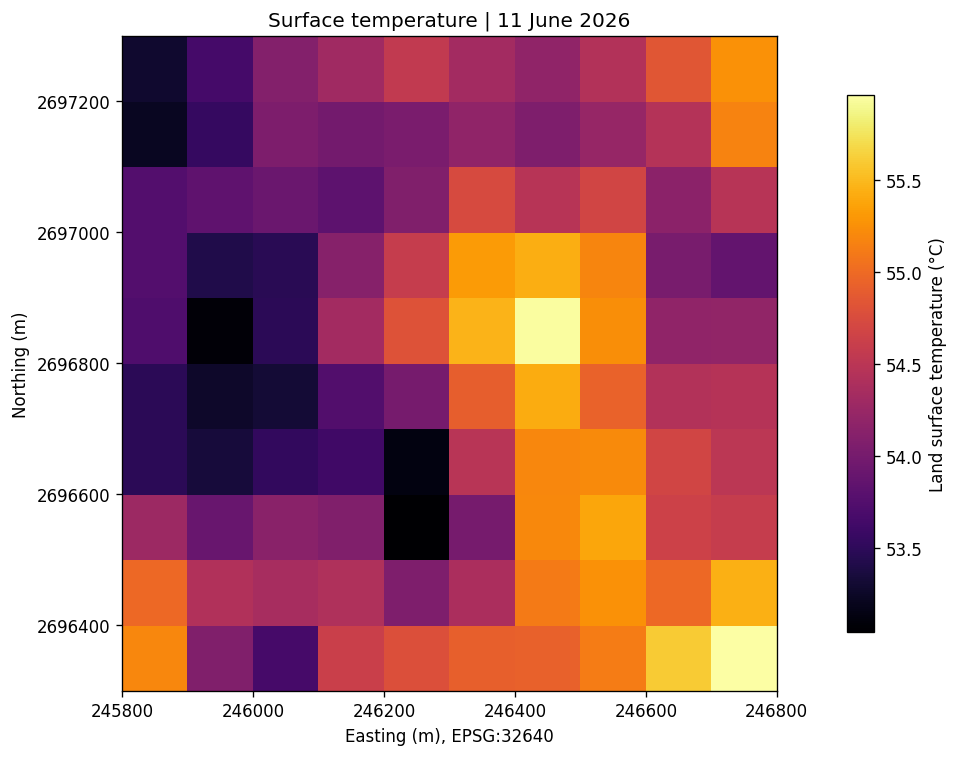

In [4]:
plot_grid(features, "lst_mean_c", "Surface temperature | 11 June 2026", "Land surface temperature (°C)", RESULTS / "surface_temperature.png")
plt.show()
print(features.loc[features.heat_usable, "lst_mean_c"].describe().round(3).to_string())


## 4. Vegetation signal

The NDVI map uses the matching Sentinel-2 acquisition on the same date. Spatial patterns are exploratory associations and need dated reference imagery or field checks for interpretation.

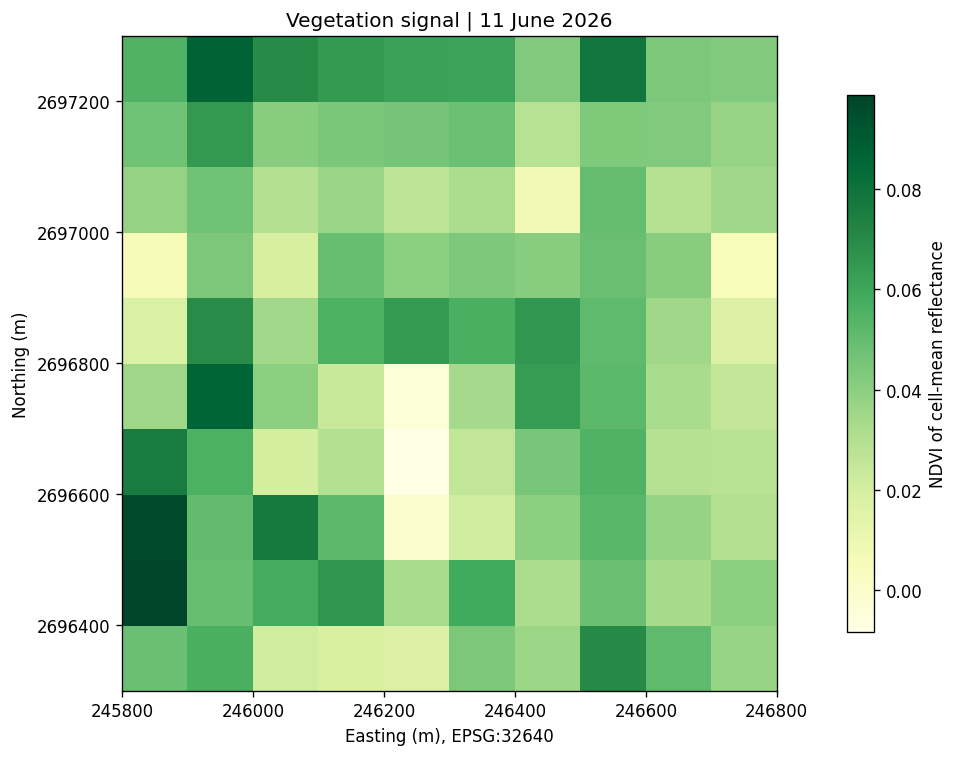

In [5]:
plot_grid(features, "ndvi", "Vegetation signal | 11 June 2026", "NDVI of cell-mean reflectance", RESULTS / "vegetation_signal.png", cmap="YlGn")
plt.show()


## 5. Provisional assessment priorities

Relative heat is cell temperature minus the median of usable cells in this window. The heat score is `100 × (average rank − 0.5) / number of usable cells`. Scores at least 90 are higher priority, 75–<90 are medium and below 75 are lower.

For the hotspot sensitivity check, use the 85th, 90th and 95th temperature percentiles, plus positive relative heat. These are exploratory within-window thresholds, not health thresholds. **One observation date cannot establish persistence.** Candidate actions are conditional site assessments.

priority
Lower     75
Medium    15
Higher    10
Hotspot counts: {'hot_q85': 15, 'hot_q90': 10, 'hot_q95': 5}
       cell_id priority  priority_score  lst_mean_c
window_r09_c09   Higher            99.5      55.960
window_r04_c06   Higher            98.5      55.938
window_r09_c08   Higher            97.5      55.599
window_r04_c05   Higher            96.5      55.464
window_r08_c09   Higher            95.5      55.445
window_r03_c06   Higher            94.5      55.434
window_r05_c06   Higher            93.5      55.415
window_r07_c07   Higher            92.5      55.384
window_r03_c05   Higher            91.5      55.320
window_r00_c09   Higher            90.5      55.263


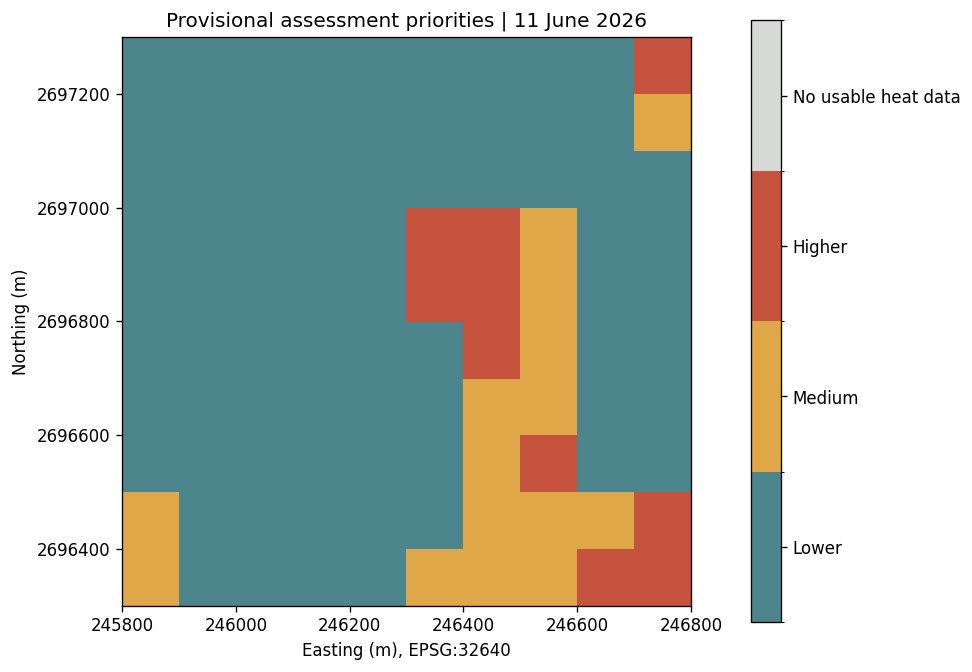

In [6]:
priorities = rank_priorities(features)
priorities.to_csv(RESULTS / "priority_table.csv", index=False)
plot_priority(priorities, RESULTS / "priority_map.png")
plt.show()
print(priorities.priority.value_counts().to_string())
print("Hotspot counts:", {q: int(priorities[q].sum()) for q in ["hot_q85", "hot_q90", "hot_q95"]})
print(priorities.sort_values("priority_rank")[["cell_id", "priority", "priority_score", "lst_mean_c"]].head(10).round(3).to_string(index=False))


## 6. Spatial validation

Four contiguous easting strips serve as test areas. Training-cell centres must be **more than 200 m** from all test-cell centres. Every eligible cell appears once in spatial testing. The target is relative temperature based on the **training-only median** in each fold.

Compare a mean baseline, scaled linear regression and a random forest (200 trees, maximum depth 8, minimum leaf size 5, seed 42). We report MAE, RMSE and R² per fold. Mean fold MAE gives every fold equal weight. This is a small-window spatial test, not evidence of future-date performance or intervention effectiveness. Temporal validation is unavailable because the sample has one date.

            model  folds  test_cells  MAE_mean_C  MAE_min_C  MAE_max_C  RMSE_mean_C  R2_mean
    Mean baseline      4         100      0.8173     0.4331     1.1117       0.9344  -2.8210
Linear regression      4         100      0.9661     0.7287     1.1627       1.1833  -4.6858
    Random forest      4         100      0.7465     0.5008     0.9766       0.8781  -2.2655


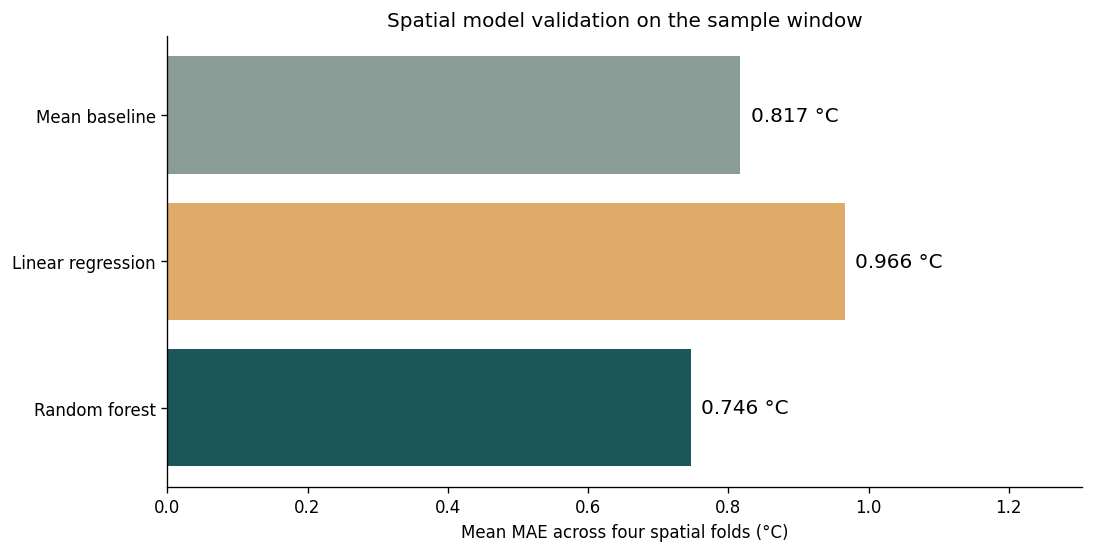

In [7]:
fold_metrics, validation = validate_models(features, RESULTS)
print(validation.round(4).to_string(index=False))
plot_validation(validation, RESULTS / "validation_comparison.png")
plt.show()


## 7. Interactive evidence map

The map uses the independent 100 m grid without external basemaps or administrative boundary polygons. Open the generated HTML to select cells, change layers and export evidence. Roof and pavement suggestions require confirmation of actual surfaces and site feasibility.

In [8]:
map_path = write_interactive_map(priorities, ROOT)
print("Created results/interactive_priority_map.html")
try:
    from IPython.display import IFrame, display
except ImportError:
    print("Open the HTML file in a browser to use the interactive map.")
else:
    display(IFrame(src="../results/interactive_priority_map.html" if Path.cwd().name == "notebooks" else "results/interactive_priority_map.html", width="100%", height=820))


Created results/interactive_priority_map.html
Open the HTML file in a browser to use the interactive map.


## 8. Output checks and limitations

The assertions check file completeness, grid coverage and the seed-controlled validation partitions. They do not validate the upstream satellite retrieval or establish causality. Results are specific to this selected 1 km² window and one date. Hyperspectral imagery and WorldCover are not inputs to this reproducible example.

Before submission, the team must confirm its registered name, official theme, represented country, members/roles and code licence, then attach the slide PDF to the platform form.

In [9]:
assert len(priorities) == 100 and not priorities.cell_id.duplicated().any()
assert validation.folds.eq(4).all() and validation.test_cells.eq(int(features.surface_usable.sum())).all()
assert all((RESULTS / name).is_file() for name in ["surface_temperature.png", "vegetation_signal.png", "priority_map.png", "validation_summary.csv", "interactive_priority_map.html"])
summary = {
    "window_area_km2": 1.0, "cell_size_m": 100, "cells": len(priorities),
    "usable_heat_cells": int(features.heat_usable.sum()), "observation_date": "2026-06-11",
    "mean_lst_c": float(features.loc[features.heat_usable, "lst_mean_c"].mean()),
    "min_lst_c": float(features.lst_mean_c.min()), "max_lst_c": float(features.lst_mean_c.max()),
    "priority_counts": {str(k): int(v) for k, v in priorities.priority.value_counts().items()},
    "validation": json.loads(validation.to_json(orient="records")),
    "persistence_established": False, "temporal_validation": "unavailable: one date",
    "administrative_sector_boundary_used": False
}
(RESULTS / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
print(json.dumps(summary, indent=2))


{
  "window_area_km2": 1.0,
  "cell_size_m": 100,
  "cells": 100,
  "usable_heat_cells": 100,
  "observation_date": "2026-06-11",
  "mean_lst_c": 54.361104812622074,
  "min_lst_c": 53.04318237304688,
  "max_lst_c": 55.95984649658203,
  "priority_counts": {
    "Lower": 75,
    "Medium": 15,
    "Higher": 10
  },
  "validation": [
    {
      "model": "Mean baseline",
      "folds": 4,
      "test_cells": 100,
      "MAE_mean_C": 0.8173195698,
      "MAE_min_C": 0.4331430138,
      "MAE_max_C": 1.1116557121,
      "RMSE_mean_C": 0.9343522531,
      "R2_mean": -2.8209938129
    },
    {
      "model": "Linear regression",
      "folds": 4,
      "test_cells": 100,
      "MAE_mean_C": 0.9661352441,
      "MAE_min_C": 0.7286643572,
      "MAE_max_C": 1.1626919692,
      "RMSE_mean_C": 1.1832645564,
      "R2_mean": -4.6858261309
    },
    {
      "model": "Random forest",
      "folds": 4,
      "test_cells": 100,
      "MAE_mean_C": 0.7464790506,
      "MAE_min_C": 0.5007693073,
      "M